# 分子の電子状態を、量子コンピュータで調べる
## IBM Quantum FTQC Hands-on workshop — 概観

対象：材料科学・量子化学・量子計算に関心のある企業人・学生。専門知識を前提にしません。

**今日の問い**：分子の2つの電子状態のエネルギー差を、量子コンピュータの測定からどのように推定するか。

**到達目標**
1. 状態準備・時間発展・測定の役割を説明する。
2. 回路の操作数と精度のトレードオフを比較する。
3. 測定からエネルギー差を推定し、不確かさと限界を述べる。

資料の図はコード実行で表示できます。IBMへの接続は行いません。

In [1]:
# GitHub → Colab / ローカルの共通セットアップ
import sys, subprocess, importlib.util
from pathlib import Path
GITHUB_REPOSITORY = "https://github.com/QS-laboratory/IBM_handson.git"
GITHUB_REF = "main"
try:
    IS_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IS_COLAB = False
if IS_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "qiskit==2.4.1", "qiskit-ibm-runtime==0.43.1", "pylatexenc==2.10"], check=True)
    checkout = Path("/content/IBM_handson")
    if not checkout.exists():
        subprocess.run(["git", "clone", GITHUB_REPOSITORY, str(checkout)], check=True)
    subprocess.run(["git", "-C", str(checkout), "fetch", "origin", GITHUB_REF, "--depth", "1"], check=True)
    subprocess.run(["git", "-C", str(checkout), "checkout", "--detach", "FETCH_HEAD"], check=True)
    WORKSHOP_ROOT = checkout / "hands_on"
else:
    candidates = [Path.cwd(), Path.cwd()/"hands_on", Path.cwd().parent]
    WORKSHOP_ROOT = next(p for p in candidates if (p/"src/workshop.py").exists())
sys.path.insert(0, str(WORKSHOP_ROOT / "src"))
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from workshop import *
import qiskit
print("Qiskit:", qiskit.__version__)
print("教材:", WORKSHOP_ROOT)
print("実機への送信は、明示的に有効化したセルだけが行います。")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

def show_circuit(qc):
    try:
        figure = qc.draw("mpl", fold=90)
        display(figure)
        plt.close(figure)
    except ImportError:
        print(qc.draw("text", fold=90))

Qiskit: 2.4.1
教材: /Users/sato/project/FTQC_HandsOn/hands_on
実機への送信は、明示的に有効化したセルだけが行います。


## 1. 材料の性質から、電子の状態へ

材料や分子が光を吸収する、電子を受け渡す、化学反応を起こすとき、電子の状態とエネルギーが関係します。
実材料では温度、環境、構造の変化、分子間相互作用も重要です。今日は対象を絞り、**原子核の位置を固定した1分子の電子状態**を扱います。

- 原子核の配置を決める。
- その配置における電子のエネルギーと状態を計算する。
- 状態間の差を読み、物性理解の一つの手掛かりにする。

**考えてみましょう**：業務や研究で関心があるのは、安定性、光、反応、電荷移動のどれでしょうか。

## 2. エチレンからポリエンへ：π電子と共役

炭素の二重結合にはσ結合とπ結合があります。平面に垂直なp軌道が重なり、π電子を分子全体へ広げます。
二重結合と単結合が交互に並ぶ共役鎖を、エチレン → 1,3-ブタジエン → 1,3,5-ヘキサトリエンと延ばして考えます。
エチレンはこの説明の入口となるアルケン、ブタジエンとヘキサトリエンはポリエンです。

今日はブタジエンを主題材とし、実機実行の初期設定は小さなエチレンです。
両分子の幾何は教材用に固定した理想化構造であり、最適化済み構造ではありません。

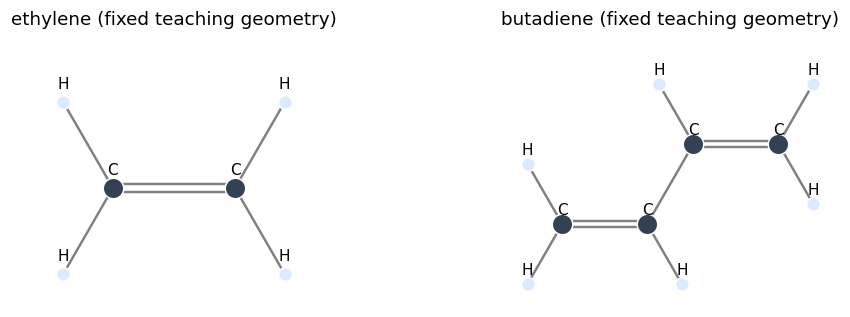

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
for name, ax in zip(["ethylene", "butadiene"], axes): plot_molecule(name, ax)
plt.tight_layout()
plt.show()

### 分子軌道を見る

下図は、STO-3G基底で計算したπ空間の分子軌道を、分子平面から0.6 Å上の断面で示したものです。
色は波動関数の符号で、電荷の正負ではありません。符号全体を反転しても同じ軌道です。
軌道は1電子の表現であり、多電子状態全体と区別します。

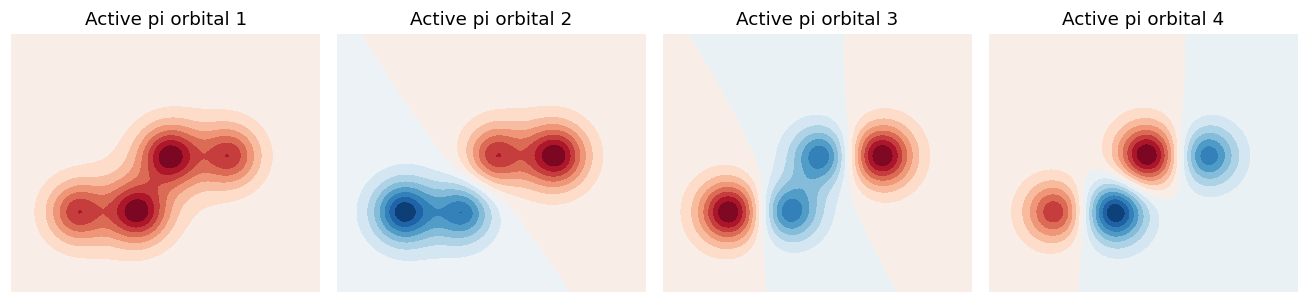

In [3]:
meta, arrays = load_model("butadiene")
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for i, ax in enumerate(axes):
    values = arrays["orbital_values"][:, :, i]
    bound = np.max(abs(values))
    ax.contourf(arrays["orbital_x"], arrays["orbital_y"], values,
                levels=np.linspace(-bound, bound, 17), cmap="RdBu_r")
    ax.set_title(f"Active pi orbital {i+1}")
    ax.set_aspect("equal"); ax.axis("off")
plt.tight_layout(); plt.show()

## 3. 基底状態・励起状態・スピン

電子はフェルミ粒子です。複数の電子を配置すると、軌道の占有だけでなくスピンの組み合わせも状態を区別します。
一重項は全スピンS=0、三重項はS=1です。三重項には異なるスピン射影の3成分があり、この教材では回路用にM_S=0を選びます。

今回の対象は、同じ原子核配置での**最低一重項 S0 と最低三重項 T1 の垂直エネルギー差**です。
三重項は光物性や励起状態の過程を考える上で重要ですが、S0–T1差は通常の許容光吸収のエネルギーとは同一ではありません。

These are CASCI/STO-3G teaching-model values, not experimental excitation energies.


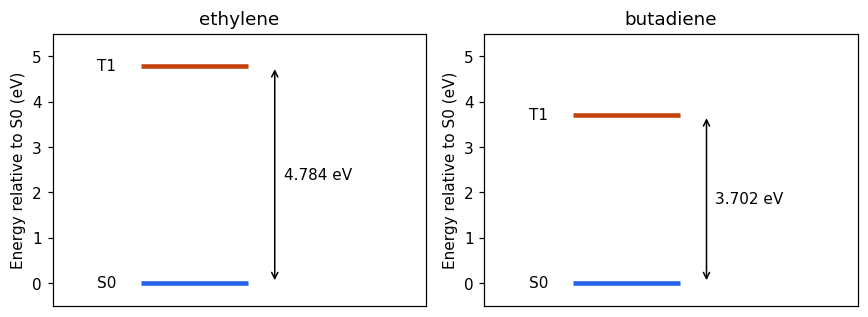

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))
for name, ax in zip(["ethylene", "butadiene"], axes):
    meta, _ = load_model(name)
    gap = meta["gap_ev"]
    ax.hlines([0, gap], -.3, .3, colors=["#2563eb", "#c2410c"], linewidth=3)
    ax.annotate("", xy=(.45, gap), xytext=(.45, 0), arrowprops={"arrowstyle":"<->"})
    ax.text(.5, gap/2, f"{gap:.3f} eV", va="center")
    ax.text(-.55, 0, "S0", va="center"); ax.text(-.55, gap, "T1", va="center")
    ax.set(xlim=(-.8, 1.3), ylim=(-.5, 5.5), title=name, ylabel="Energy relative to S0 (eV)", xticks=[])
plt.tight_layout(); plt.show()
print("These are CASCI/STO-3G teaching-model values, not experimental excitation energies.")

## 4. 基底関数・電子相関・活性空間

**基底関数**：電子の空間的な広がりを表現する部品です。今日は小さなSTO-3Gを使います。

**電子相関**：電子どうしの影響を、独立した1電子の描像より詳しく扱うことです。
平均場のHartree–Fockだけでは記述しにくい状態があり、複数の電子配置を重ね合わせます。

**活性空間**：すべての軌道を同じ精度で扱う代わりに、今回はπ電子・π軌道を選んで、その中の配置を漏れなく扱うCASCIを使います。
残りの占有軌道は二重占有で凍結します。CASCIでは軌道を固定して配置を混ぜます。CASSCFの軌道最適化は行っていません。

| 分子 | 活性電子・空間軌道 | 系量子ビット | 補助込み |
|---|---|---:|---:|
| エチレン | 2電子・2軌道 | 4 | 5 |
| ブタジエン | 4電子・4軌道 | 8 | 9 |
| ヘキサトリエン（Kanno論文） | 6電子・6軌道 | 12 | 13 |

1空間軌道にα・βの2スピン軌道があり、通常のJordan–Wigner変換ではそれぞれを1量子ビットにします。
量子ビット削減は今回は行いません。基底関数を小さくする近似と、活性空間を絞る近似は別です。

**正解の階層**：教材模型の厳密解 ≠ 基底・活性空間を拡大した解 ≠ 実験値。
今回の基準値は、この固定構造・基底・活性空間の中の厳密解です。

## 5. エネルギーを位相から読む：FTQCとの関係

固有状態の時間発展は $e^{-iHt}|E\rangle=e^{-iEt}|E\rangle$（$\hbar=1$）です。
2状態を重ね合わせると、エネルギー差が相対的な位相の変化として現れます。
適切に干渉させて測定すると、その差を推定できます。測定の1回でエネルギーが直接表示されるわけではありません。

1. **状態準備**：対象の2状態の重ね合わせを作る。
2. **時間発展**：相対的な位相を蓄積する。
3. **逆の状態準備と測定**：干渉を確率へ変換する。
4. **古典計算**：複数の測定結果からエネルギー差を推定する。

FTQCは誤り訂正を使って長い量子計算を信頼できる形で実行する構想です。
位相推定はその重要なアルゴリズムですが、今回使うIBM実機は誤り訂正済みFTQCではありません。
短く工夫した回路で、現在の実機でも原理を試します。

## 6. Kanno論文と今日の実験

Kannoらは、基底・励起状態の重ね合わせ準備と短時間発展をテンソルネットワークを使って浅い回路に近似し、位相差推定を実機で実行しました。
Hubbard模型は系32＋補助1量子ビット、分子の本編はヘキサトリエンの系12＋補助1量子ビットです。
分子では軌道の局在化と並べ替えも工夫し、最低一重項–三重項の差を対象にしています。

**論文を読むときの観点**：大きな回路を実行できたこと、信号が得られたこと、高精度で正解したこと、量子優位性を示したことは、それぞれ別の評価です。
論文の分子実機結果には大きな不確かさがあり、今回も誤差を含めて読み解きます。

**今日の教材との違い**
- 同じ分子系列とS0–T1差を扱いますが、論文の数値再現ではありません。
- 状態準備は実数RY/CX回路の事前最適化、時間発展はPauli積の短い回路を使う説明用実装です。
- 本編の回路最適化は密な小規模計算で、論文のMPS/MPOによる大規模最適化とは異なります。
- Fire Opalは基本演習の必須条件にしていません。

**当日の流れ**：準備 → 回路を比較し実機投入 → 結果から推定を更新 → 不確かさと今後の課題を討論。

**出典**
- Kanno et al., PNAS 122, e2425026122 (2025), 本文Fig. 3–5・補足S1–S3： https://doi.org/10.1073/pnas.2425026122
- 活性空間とCASCI： https://pyscf.org/user/mcscf.html
- 電子配置とFCI： https://pyscf.org/user/ci.html

**振り返り**：何の分子の、どの2状態の差を、どんな近似で求めるのか、自分の言葉で説明してください。